# Machine Learning as an Aid Against Phishing and Fraud
---
## Authors:
Alan Becker,
Alexander Zambie,
Brennan Slate,
and Lazaro Martinez Jimenez


## Dataset Choice
This project is using the [Phishing Email Dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset) from Kaggle. This dataset contains approximately 82,500 emails, with 42,891 labeled as phishing and 39,595 as legitimate. The emails are sourced from Enron, Ling, CEAS, Nazario, SpamAssassin, and Nigerian Fraud emails. For this project, we will focus on the CEAS subset, as it provides more relevant features and is less dated.

## Prediction Goal and Predictors
The goal of this project is to compare different machine learning models that can distinguish between phishing and legitimate emails based on their content.


We plan to use the columns `subject`, `body`, `sender`, and `urls` to predict the `label` column, which indicates whether an email is phishing or legitimate.









In [4]:
# packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer

## Read Data

In [5]:
df = pd.read_csv('data/CEAS_08.csv')

## Data Preprocessing


Preparing the data for modeling by dropping unnecessary columns and handling missing values.

In [6]:
df = df.drop(["receiver", "date"], axis=1)
df = df.fillna('')

## Data Exploration and Visualization


In [7]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39154 entries, 0 to 39153
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   sender   39154 non-null  object
 1   subject  39154 non-null  object
 2   body     39154 non-null  object
 3   label    39154 non-null  int64 
 4   urls     39154 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 1.5+ MB


,sender,subject,body,label,urls
0,Young Esposito <Young@iworld.de>,Never agree to be a loser,"Buck up, your troubles caused by small dimensi...",1,1
1,Mok <ipline's1983@icable.ph>,Befriend Jenna Jameson,\nUpgrade your sex and pleasures with these te...,1,1
2,Daily Top 10 <Karmandeep-opengevl@universalnet...,CNN.com Daily Top 10,>+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+=+...,1,1
3,Michael Parker <ivqrnai@pobox.com>,Re: svn commit: r619753 - in /spamassassin/tru...,Would anyone object to removing .so from this ...,0,1
4,Gretchen Suggs <externalsep1@loanofficertool.com>,SpecialPricesPharmMoreinfo,\nWelcomeFastShippingCustomerSupport\nhttp://7...,1,1


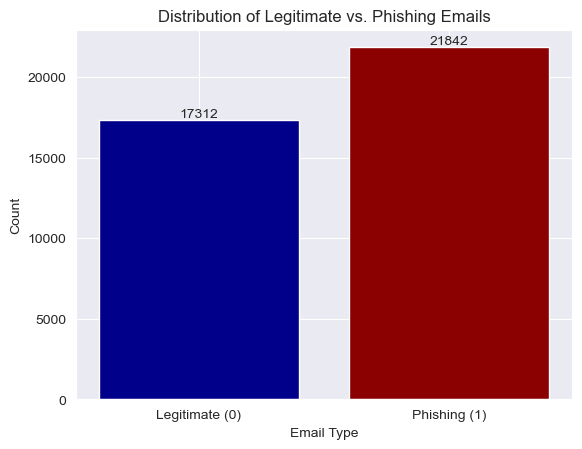

In [8]:
count = df['label'].value_counts()
bars = plt.bar(count.index, count.values, color=['darkred', 'darkblue'])
plt.title('Distribution of Legitimate vs. Phishing Emails')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.xticks([0, 1], ['Legitimate (0)', 'Phishing (1)'])
plt.bar_label(bars, fmt='%d', fontsize=10)
plt.show()

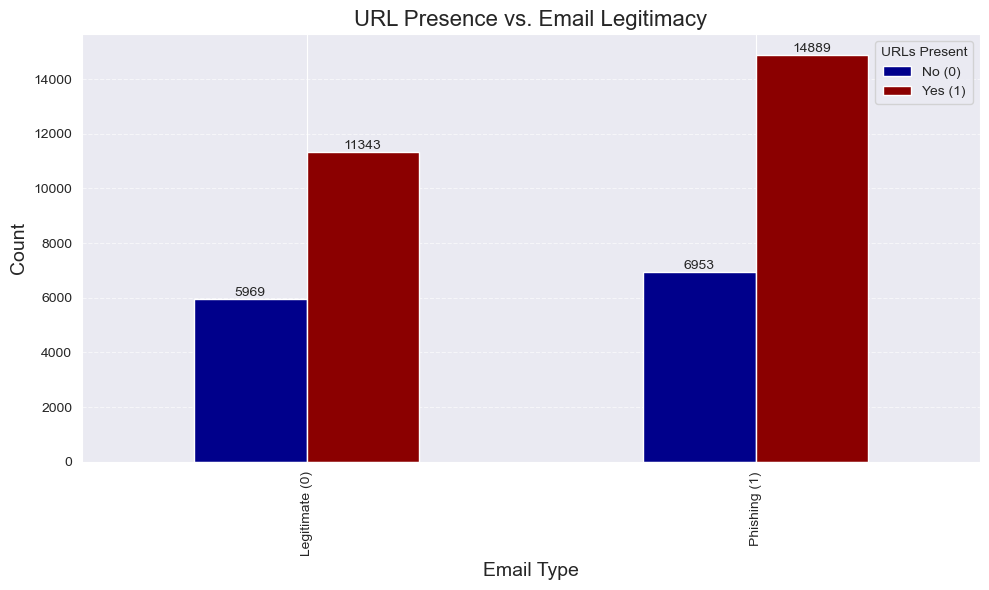

In [9]:
plot_data = pd.crosstab(df['label'], df['urls'])
fig, ax = plt.subplots(figsize=(10, 6))
plot_data.plot(kind='bar', ax=ax, color=['darkblue', 'darkred'])
ax.set_title('URL Presence vs. Email Legitimacy', fontsize=16)
ax.set_xlabel('Email Type', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.set_xticklabels(['Legitimate (0)', 'Phishing (1)'])
ax.legend(title='URLs Present', labels=['No (0)', 'Yes (1)'], loc='upper right')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Machine Learning


In [10]:
df['predictor'] = (df['subject'] + ' ' + df['body'] + ' ' + df['sender']) + ' ' + df['urls'].astype(str)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['predictor'])
y = df['label'].values
# Splitting the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)